<a href="https://colab.research.google.com/github/LorenzoMedina-lab/CodePro_Regresion_Logistica/blob/main/Mision_2_Churn_Notebook_Defensa.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Misión 2 — Predicción de abandono de clientes
**Modelo:** regresión logística  
**Dataset:** `Telco-Customer-Churn.csv`  
**Objetivo:** predecir si un cliente abandona el servicio (`Churn = 1`) o permanece (`Churn = 0`) y evaluar el modelo mediante Accuracy, Precision y Recall.

## 1. Análisis exploratorio de datos (EDA)
Antes de entrenar comprobamos la calidad de los registros, la distribución de `Churn` y la relación con características de los clientes.

### 1.1 Conexión a Google Drive
En Colab montamos Drive para acceder al archivo CSV.

In [ ]:
from google.colab import drive

# Conectamos Google Drive para acceder al archivo CSV.
drive.mount('/content/drive')

Mounted at /content/drive


### 1.2 Carga del dataset
Leemos el mismo archivo de Google Drive que se utilizó en la exploración inicial.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Cargamos el dataset original desde Google Drive.
ruta_archivo = '/content/drive/MyDrive/CodePro5.0/Telco-Customer-Churn.csv'
df_churn = pd.read_csv(ruta_archivo)

# Verificamos las primeras filas.
df_churn.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


### 1.3 Estructura y calidad de datos
Revisamos dimensiones, tipos, datos ausentes y registros repetidos.

In [ ]:
# Revisamos el tamaño, los tipos de datos y los valores faltantes.
print('Filas y columnas:', df_churn.shape)
df_churn.info()
print('\nValores faltantes por columna:')
print(df_churn.isnull().sum())

# Comprobamos si hay filas completamente repetidas.
print('\nFilas duplicadas:', df_churn.duplicated().sum())

Filas y columnas: (7043, 21)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBill

### 1.4 Revisión de `TotalCharges`
`TotalCharges` figura como texto; buscamos importes que no se puedan convertir a números. Esta columna no se utilizará para entrenar nuestro modelo simplificado.

In [ ]:
# TotalCharges parece representar importes, pero está guardada como texto.
# Contamos los valores que no pueden convertirse a números.
total_cargos_numericos = pd.to_numeric(df_churn['TotalCharges'], errors='coerce')
print('TotalCharges no numéricos:', total_cargos_numericos.isnull().sum())

TotalCharges no numéricos: 11


### 1.5 Distribución de la variable objetivo
Contamos cuántos clientes permanecieron y cuántos abandonaron el servicio.

Churn
No     5174
Yes    1869
Name: count, dtype: int64

Porcentajes:
Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


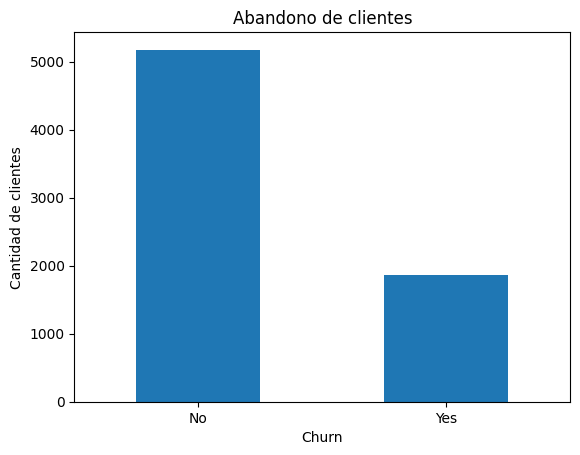

In [ ]:
# Contamos los clientes que permanecieron y los que abandonaron.
print(df_churn['Churn'].value_counts())
print('\nPorcentajes:')
print(df_churn['Churn'].value_counts(normalize=True) * 100)

# Graficamos la distribución de la variable objetivo.
df_churn['Churn'].value_counts().plot(kind='bar')
plt.title('Abandono de clientes')
plt.xlabel('Churn')
plt.ylabel('Cantidad de clientes')
plt.xticks(rotation=0)
plt.show()

### 1.6 Antigüedad y cuota mensual según Churn
Comparamos características numéricas entre clientes que permanecen y clientes que abandonan.

Antigüedad promedio (meses):
Churn
No     37.569965
Yes    17.979133
Name: tenure, dtype: float64

Cuota mensual promedio:
Churn
No     61.265124
Yes    74.441332
Name: MonthlyCharges, dtype: float64


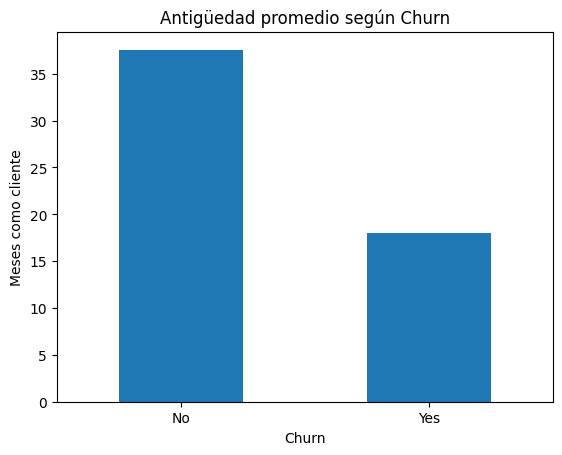

In [ ]:
# Comparamos la antigüedad y la cuota mensual promedio según Churn.
print('Antigüedad promedio (meses):')
print(df_churn.groupby('Churn')['tenure'].mean())

print('\nCuota mensual promedio:')
print(df_churn.groupby('Churn')['MonthlyCharges'].mean())

# Visualizamos la antigüedad promedio por grupo.
df_churn.groupby('Churn')['tenure'].mean().plot(kind='bar')
plt.title('Antigüedad promedio según Churn')
plt.xlabel('Churn')
plt.ylabel('Meses como cliente')
plt.xticks(rotation=0)
plt.show()

## 2. Preparación de variables
`X` contiene las tres características elegidas; `y` contiene la respuesta real: abandono (1) o permanencia (0). Seleccionamos columnas numéricas para mantener un modelo sencillo. Verificamos que no falten valores en esas columnas.

In [ ]:
# Elegimos tres características numéricas fáciles de interpretar.
X = df_churn[['tenure', 'MonthlyCharges', 'SeniorCitizen']]

# Convertimos Churn a 0 (permanece) y 1 (abandona).
y = df_churn['Churn'].map({'No': 0, 'Yes': 1})

print('Características utilizadas:')
print(X.head())
print('\nValores faltantes en X:')
print(X.isnull().sum())
print('\nValores faltantes en y:', y.isnull().sum())

Características utilizadas:
   tenure  MonthlyCharges  SeniorCitizen
0       1           29.85              0
1      34           56.95              0
2       2           53.85              0
3      45           42.30              0
4       2           70.70              0

Valores faltantes en X:
tenure            0
MonthlyCharges    0
SeniorCitizen     0
dtype: int64

Valores faltantes en y: 0


## 3. División Train/Test
Usamos 80% de los clientes para entrenamiento y 20% para prueba. `random_state=42` hace reproducible la división y `stratify=y` conserva aproximadamente la proporción de abandono en ambos conjuntos.

In [ ]:
from sklearn.model_selection import train_test_split

# Reservamos el 20% para probar el modelo con datos no vistos.
X_entrenamiento, X_prueba, y_entrenamiento, y_prueba = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print('Clientes de entrenamiento:', len(X_entrenamiento))
print('Clientes de prueba:', len(X_prueba))

Clientes de entrenamiento: 5634
Clientes de prueba: 1409


## 4. Entrenamiento del modelo
La regresión logística aprende patrones para estimar si un cliente pertenece a la categoría 0 o 1.

In [ ]:
from sklearn.linear_model import LogisticRegression

# Creamos el modelo y aprendemos a partir de los clientes de entrenamiento.
modelo_logistico = LogisticRegression(max_iter=1000)
modelo_logistico.fit(X_entrenamiento, y_entrenamiento)

print('Modelo entrenado correctamente.')

Modelo entrenado correctamente.


## 5. Predicciones sobre prueba
El modelo predice Churn en clientes que no utilizó durante el entrenamiento.

In [ ]:
# Predecimos si los clientes del conjunto de prueba abandonan (1) o no (0).
predicciones = modelo_logistico.predict(X_prueba)

# Comparamos algunas respuestas reales con las predichas.
comparacion = pd.DataFrame({
    'Churn real': y_prueba,
    'Churn predicho': predicciones
})
comparacion.head(10)

,Churn real,Churn predicho
437,0,0
2280,0,1
2235,0,0
4460,0,0
3761,0,0
5748,0,1
3568,0,1
2976,0,0
5928,0,0
1639,1,0


## 6. Evaluación: Accuracy, Precision y Recall
Evaluamos las predicciones usando las tres métricas solicitadas. La clase positiva es `1` (el cliente abandona).

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score

# Evaluamos las predicciones realizadas sobre los datos de prueba.
accuracy = accuracy_score(y_prueba, predicciones)
precision = precision_score(y_prueba, predicciones)
recall = recall_score(y_prueba, predicciones)

print('Accuracy:', round(accuracy, 3))
print('Precision:', round(precision, 3))
print('Recall:', round(recall, 3))

Accuracy: 0.784
Precision: 0.627
Recall: 0.455


## 7. Interpretación de resultados
Expresamos las métricas obtenidas sobre la prueba en porcentajes. Dado que hay más clientes que permanecen, Accuracy debe leerse junto con Precision y Recall.

In [ ]:
# Expresamos las tres métricas en un lenguaje más fácil de comunicar.
print(f'Accuracy: aproximadamente {accuracy * 100:.1f}% de las predicciones son correctas.')
print(f'Precision: aproximadamente {precision * 100:.1f}% de los clientes señalados como abandono realmente abandonaron.')
print(f'Recall: se detectó aproximadamente {recall * 100:.1f}% de los clientes que realmente abandonaron.')

Accuracy: aproximadamente 78.4% de las predicciones son correctas.
Precision: aproximadamente 62.7% de los clientes señalados como abandono realmente abandonaron.
Recall: se detectó aproximadamente 45.5% de los clientes que realmente abandonaron.


## 8. Conclusión

Se exploró el dataset y se detectó que existe una diferencia importante entre la cantidad de clientes que permanecen y los que abandonan. También se revisó `TotalCharges`, almacenada como texto; para mantener el alcance simple, el modelo utiliza únicamente `tenure`, `MonthlyCharges` y `SeniorCitizen`, sin valores faltantes en la exploración inicial.

Los datos se dividieron en **80% de entrenamiento** y **20% de prueba**, conservando la proporción de las dos clases. Se entrenó una **regresión logística** y se evaluó con **Accuracy, Precision y Recall**.

**Interpretación:** Accuracy mide los aciertos generales, Precision evalúa la fiabilidad de los avisos de abandono y Recall indica qué parte de los abandonos reales logramos detectar. Como la clase `No` es mayoritaria, ninguna de las tres métricas debe interpretarse de manera aislada.

Una funcion que reciba como parametro 'tenure', 'MonthlyCharges', 'SeniorCitizen' y utilice el modelo para predecir si customerID  abandona o no el servicio y dar una respuesta del usuario con su prediccion

---



In [ ]:
print(X_prueba)

      tenure  MonthlyCharges  SeniorCitizen
437       72          114.05              0
2280       8          100.15              1
2235      41           78.35              0
4460      18           78.20              0
3761      72           82.65              0
...      ...             ...            ...
5143      49           87.20              0
4439      28           20.30              0
3857       5           20.65              0
4758      56           19.70              0
5613      72           70.45              0

[1409 rows x 3 columns]


In [ ]:
def predecir_contininuidad_cliente(dato):

cliente = modelo_logistico.predict(X_prueba(dato))


#comparacion = pd.DataFrame({
    'Churn real': y_prueba,
    'Segun El modelo': cliente})

print(cliente)

  #print(f'El cliente  de las predicciones son correctas.')





predecir_contininuidad_cliente(X_prueba('tenure'.head(0)))


SyntaxError: unmatched '}' (3706212204.py, line 8)